In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../../datasets/heart.csv")

print(df.head())
print(df.shape)
print(df.dtypes)

   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   52    1   0       125   212    0        1      168      0      1.0      2   
1   53    1   0       140   203    1        0      155      1      3.1      0   
2   70    1   0       145   174    0        1      125      1      2.6      0   
3   61    1   0       148   203    0        1      161      0      0.0      2   
4   62    0   0       138   294    1        1      106      0      1.9      1   

   ca  thal  target  
0   2     3       0  
1   0     3       0  
2   0     3       0  
3   1     3       0  
4   3     2       0  
(1025, 14)
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64
dtype: object


In [2]:
numerical_df = df.select_dtypes(include=["number"])

columns = list(numerical_df.columns)
n = len(columns)

print("Numerical Columns:", columns)
print("Total Numerical Columns:", n)

Numerical Columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']
Total Numerical Columns: 14


In [3]:
def manual_correlation(x, y):
    x = list(x)
    y = list(y)

    valid_pairs = [
        (a, b) for a, b in zip(x, y)
        if pd.notna(a) and pd.notna(b)
    ]

    if len(valid_pairs) < 2:
        return 0

    x = [pair[0] for pair in valid_pairs]
    y = [pair[1] for pair in valid_pairs]

    mean_x = sum(x) / len(x)
    mean_y = sum(y) / len(y)

    numerator = 0
    sum_sq_x = 0
    sum_sq_y = 0

    for i in range(len(x)):
        dx = x[i] - mean_x
        dy = y[i] - mean_y

        numerator += dx * dy
        sum_sq_x += dx ** 2
        sum_sq_y += dy ** 2

    denominator = (sum_sq_x * sum_sq_y) ** 0.5

    if denominator == 0:
        return 0

    return numerator / denominator


correlation_matrix = []

for col1 in columns:
    row = []

    for col2 in columns:
        correlation = manual_correlation(
            numerical_df[col1],
            numerical_df[col2]
        )
        row.append(correlation)

    correlation_matrix.append(row)

correlation_df = pd.DataFrame(
    correlation_matrix,
    index=columns,
    columns=columns
)

print(correlation_df.round(2))

           age   sex    cp  trestbps  chol   fbs  restecg  thalach  exang  \
age       1.00 -0.10 -0.07      0.27  0.22  0.12    -0.13    -0.39   0.09   
sex      -0.10  1.00 -0.04     -0.08 -0.20  0.03    -0.06    -0.05   0.14   
cp       -0.07 -0.04  1.00      0.04 -0.08  0.08     0.04     0.31  -0.40   
trestbps  0.27 -0.08  0.04      1.00  0.13  0.18    -0.12    -0.04   0.06   
chol      0.22 -0.20 -0.08      0.13  1.00  0.03    -0.15    -0.02   0.07   
fbs       0.12  0.03  0.08      0.18  0.03  1.00    -0.10    -0.01   0.05   
restecg  -0.13 -0.06  0.04     -0.12 -0.15 -0.10     1.00     0.05  -0.07   
thalach  -0.39 -0.05  0.31     -0.04 -0.02 -0.01     0.05     1.00  -0.38   
exang     0.09  0.14 -0.40      0.06  0.07  0.05    -0.07    -0.38   1.00   
oldpeak   0.21  0.08 -0.17      0.19  0.06  0.01    -0.05    -0.35   0.31   
slope    -0.17 -0.03  0.13     -0.12 -0.01 -0.06     0.09     0.40  -0.27   
ca        0.27  0.11 -0.18      0.10  0.07  0.14    -0.08    -0.21   0.11   

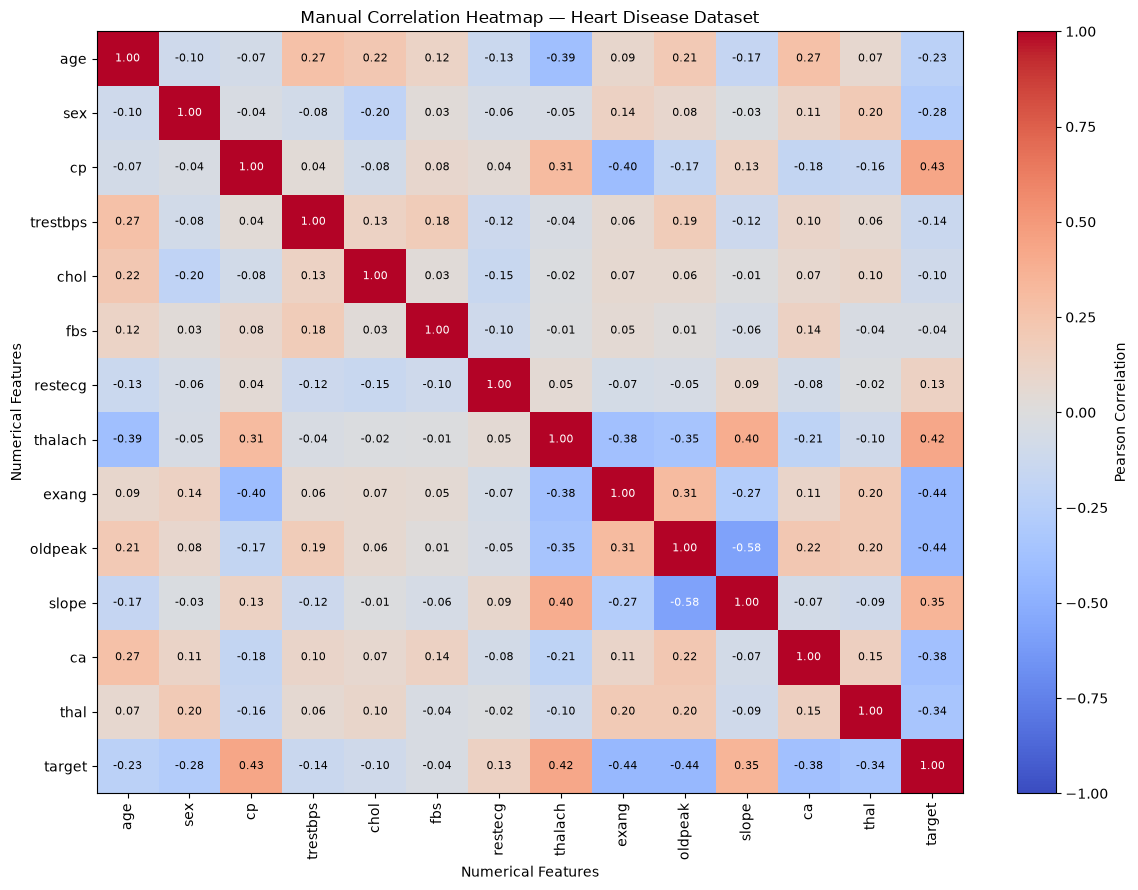

In [4]:
fig, ax = plt.subplots(figsize=(12, 9))

image = ax.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    aspect="auto"
)

ax.set_xticks(range(n))
ax.set_yticks(range(n))

ax.set_xticklabels(columns, rotation=90)
ax.set_yticklabels(columns)

for i in range(n):
    for j in range(n):
        value = correlation_matrix[i][j]

        text_color = "white" if abs(value) > 0.55 else "black"

        ax.text(
            j, i, f"{value:.2f}",
            ha="center",
            va="center",
            color=text_color,
            fontsize=8
        )

ax.set_title("Manual Correlation Heatmap — Heart Disease Dataset")
ax.set_xlabel("Numerical Features")
ax.set_ylabel("Numerical Features")

colorbar = fig.colorbar(image, ax=ax)
colorbar.set_label("Pearson Correlation")

plt.tight_layout()
plt.show()

In [5]:
strong_correlations = []

for i in range(n):
    for j in range(i + 1, n):
        value = correlation_matrix[i][j]

        if abs(value) >= 0.5:
            strong_correlations.append(
                (columns[i], columns[j], value)
            )

strong_correlations.sort(
    key=lambda item: abs(item[2]),
    reverse=True
)

print("Strong Correlations (|r| >= 0.5):\n")

if strong_correlations:
    for col1, col2, value in strong_correlations:
        print(f"{col1} vs {col2}: {value:.3f}")
else:
    print("No feature pairs found with |r| >= 0.5")

Strong Correlations (|r| >= 0.5):

oldpeak vs slope: -0.575


## Conclusion

In this task, Pearson correlation coefficients were calculated manually
without using built-in correlation functions. A custom correlation
heatmap was created using Matplotlib to visualize relationships between
numerical features. Strongly correlated feature pairs were also identified.